# NN_L5_lstm_gates

**Mean forget-gate and input-gate activations of the trained volatility LSTM (seed 20261108) over the S&P 500 test period 2020-2026.**

Neural Networks and Deep Learning (NN), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L5/NN_L5_lstm_gates/NN_L5_lstm_gates.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Gate activations at the last step of each 22-day window, 5-day means.

mean forget gate = 0.547   [gates.f_mean]
mean input gate = 0.544   [gates.i_mean]
corr(forget gate, log variance today) = 0.743   [gates.f_corr_y]


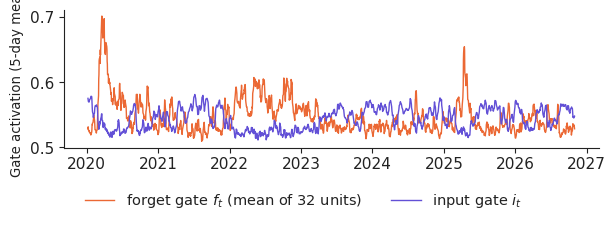

In [3]:
import json, urllib.request
_F = 'lstm_gates_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L5/NN_L5_lstm_gates/' + _F))
import matplotlib.dates as mdates
t = pd.to_datetime(R['date']); f = np.array(R['f']); i = np.array(R['i'])
show('gates.f_mean', 'mean forget gate', round(float(f.mean()), 3)); show('gates.i_mean', 'mean input gate', round(float(i.mean()), 3))
show('gates.f_corr_y', 'corr(forget gate, log variance today)', round(float(np.corrcoef(f, R['ylag'])[0, 1]), 3))
fig, ax = plt.subplots(figsize=(6.4, 2.3)); ax.plot(t, pd.Series(f).rolling(5).mean(), color=PAL['model'], lw=1, label='forget gate $f_t$ (mean of 32 units)')
ax.plot(t, pd.Series(i).rolling(5).mean(), color='#6250d6', lw=1, label='input gate $i_t$'); ax.set_ylabel('Gate activation (5-day mean)', fontsize=9.5)
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y')); legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, .15, 1, 1))
fig.savefig('lstm_gates.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()